Import Libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Load the dataset


In [ ]:
df = pd.read_csv("employee_attrition_classification.csv")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   department              244 non-null    object 
 1   work_accident           248 non-null    object 
 2   emp_id                  241 non-null    object 
 3   left_company            239 non-null    float64
 4   salary_k                242 non-null    float64
 5   education_level         236 non-null    object 
 6   promotion_last_5years   241 non-null    object 
 7   years_at_company        236 non-null    float64
 8   salary_k_dup            242 non-null    float64
 9   last_performance_score  240 non-null    float64
dtypes: float64(5), object(5)
memory usage: 20.6+ KB


In [ ]:
df.head()

,department,work_accident,emp_id,left_company,salary_k,education_level,promotion_last_5years,years_at_company,salary_k_dup,last_performance_score
0,Finance,No,E60000,0.0,53.06,BACHELORS,No,14.0,53.06,1.0
1,Support,o,E60001,1.0,82.23,PhD,NaN,16.0,82.23,3.0
2,NaN,N,E60002,0.0,165.15,MASTERS,o,14.0,165.15,4.0
3,Sales,NO,NaN,0.0,51.28,NaN,NaN,9.0,51.28,NaN
4,Sales,NO,E60004,1.0,39.74,Bachelors,o,27.0,39.74,4.0


In [ ]:
df.tail()

,department,work_accident,emp_id,left_company,salary_k,education_level,promotion_last_5years,years_at_company,salary_k_dup,last_performance_score
257,HR,o,E60139,0.0,189.30,NaN,N,11.0,189.30,3.0
258,Suport,N,NaN,0.0,53.67,High School,o,8.0,53.67,5.0
259,FINANCE,NO,E60126,NaN,98.89,PhD,NO,7.0,98.89,2.0
260,Sales,Yes,E60076,1.0,168.88,High School,No,27.0,168.88,2.0
261,Finance,No,E60098,0.0,55.46,NaN,No,NaN,55.46,2.0


In [ ]:
print(df.shape)

(262, 10)


In [ ]:
print(df.columns)

Index(['department', 'work_accident', 'emp_id', 'left_company', 'salary_k',
       'education_level', 'promotion_last_5years', 'years_at_company',
       'salary_k_dup', 'last_performance_score'],
      dtype='object')


In [ ]:
print(df.describe)

<bound method NDFrame.describe of     department work_accident  emp_id  left_company  salary_k education_level  \
0      Finance            No  E60000           0.0     53.06       BACHELORS   
1      Support             o  E60001           1.0     82.23             PhD   
2          NaN             N  E60002           0.0    165.15         MASTERS   
3        Sales            NO     NaN           0.0     51.28             NaN   
4        Sales            NO  E60004           1.0     39.74       Bachelors   
..         ...           ...     ...           ...       ...             ...   
257         HR             o  E60139           0.0    189.30             NaN   
258     Suport             N     NaN           0.0     53.67     High School   
259    FINANCE            NO  E60126           NaN     98.89             PhD   
260      Sales           Yes  E60076           1.0    168.88     High School   
261    Finance            No  E60098           0.0     55.46             NaN   

    p

Missing values in each column

In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
department                18
work_accident             14
emp_id                    21
left_company              23
salary_k                  20
education_level           26
promotion_last_5years     21
years_at_company          26
salary_k_dup              20
last_performance_score    22
dtype: int64


Exact duplicate rows

In [ ]:
print("\nExact duplicate rows:")
print(df.duplicated().sum())


Exact duplicate rows:
12


Convert all employee IDs to NaN

In [ ]:
df["emp_id"] = np.nan
print(df["emp_id"])

0     NaN
1     NaN
2     NaN
3     NaN
4     NaN
       ..
257   NaN
258   NaN
259   NaN
260   NaN
261   NaN
Name: emp_id, Length: 262, dtype: float64



Fill all NaN values using NumPy

In [ ]:
df["emp_id"] = np.where(
    np.isnan(df["emp_id"]),
    np.arange(1, len(df) + 1),
    df["emp_id"]
)
df

,department,work_accident,emp_id,left_company,salary_k,education_level,promotion_last_5years,years_at_company,salary_k_dup,last_performance_score
0,Finance,No,1.0,0.0,53.06,BACHELORS,No,14.0,53.06,1.0
1,Support,o,2.0,1.0,82.23,PhD,NaN,16.0,82.23,3.0
2,NaN,N,3.0,0.0,165.15,MASTERS,o,14.0,165.15,4.0
3,Sales,NO,4.0,0.0,51.28,NaN,NaN,9.0,51.28,NaN
4,Sales,NO,5.0,1.0,39.74,Bachelors,o,27.0,39.74,4.0
...,...,...,...,...,...,...,...,...,...,...
257,HR,o,258.0,0.0,189.30,NaN,N,11.0,189.30,3.0
258,Suport,N,259.0,0.0,53.67,High School,o,8.0,53.67,5.0
259,FINANCE,NO,260.0,NaN,98.89,PhD,NO,7.0,98.89,2.0
260,Sales,Yes,261.0,1.0,168.88,High School,No,27.0,168.88,2.0


Verify

In [ ]:
print(df["emp_id"])
print("Missing values:", df["emp_id"].isnull().sum())

0        1.0
1        2.0
2        3.0
3        4.0
4        5.0
       ...  
257    258.0
258    259.0
259    260.0
260    261.0
261    262.0
Name: emp_id, Length: 262, dtype: float64
Missing values: 0


Drop duplicate salary column

In [ ]:
df.drop(columns=["salary_k_dup"], inplace=True)

In [ ]:
print(df.columns)

Index(['department', 'work_accident', 'emp_id', 'left_company', 'salary_k',
       'education_level', 'promotion_last_5years', 'years_at_company',
       'last_performance_score'],
      dtype='object')


In [ ]:

df = df.drop_duplicates().copy()
print("Rows after cleaning:", df.shape[0])

Rows after cleaning: 262


Department cleaning

In [ ]:
department_map = {
    "finance": "Finance",
    "finace": "Finance",
    "financ": "Finance",
    "inance": "Finance",
    "support": "Support",
    "suport": "Support",
    "suppot": "Support",
    "suppor": "Support",
    "spport": "Support",
    "upport": "Support",
    "sales": "Sales",
    "sals": "Sales",
    "saes": "Sales",
    "ales": "Sales",
    "engineering": "Engineering",
    "engineerig": "Engineering",
    "engneering": "Engineering",
    "hr": "HR",
    "h": "HR",
    "r": "HR"
}

Fill missing department values with the mode

In [ ]:
department_mode = df["department"].mode()[0]
df["department"].fillna(department_mode, inplace=True)
print("Missing values after filling:")
print(df["department"].isnull().sum())

Missing values after filling:
0


/tmp/ipykernel_380/3562703147.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["department"].fillna(department_mode, inplace=True)


educatin column cleaning

In [ ]:
education_map = {
    "bachelors": "Bachelors",
    "bacelors": "Bachelors",
    "bachelos": "Bachelors",
    "bacheors": "Bachelors",
    "bachlors": "Bachelors",
    "bahelors": "Bachelors",
    "achelors": "Bachelors",
    "masters": "Masters",
    "masers": "Masters",
    "maters": "Masters",
    "msters": "Masters",
    "phd": "PhD",
    "ph": "PhD",
    "pd": "PhD",
    "hd": "PhD",
    "high school": "High School",
    "highschool": "High School",
    "high schol": "High School",
    "high scool": "High School",
    "high chool": "High School",
    "hig school": "High School",
    "igh school": "High School"
}


In [ ]:
df["education_level"].fillna(df["education_level"].mode()[0], inplace=True)
print("Missing values after filling:")
print(df["education_level"].isnull().sum())

Missing values after filling:
0


/tmp/ipykernel_380/3513347997.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["education_level"].fillna(df["education_level"].mode()[0], inplace=True)


In [ ]:
df["salary_k"].fillna(df["salary_k"].mean(), inplace=True)
print("Missing values after filling:")
print(df["salary_k"].isnull().sum())

Missing values after filling:
0


/tmp/ipykernel_380/4179121864.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["salary_k"].fillna(df["salary_k"].mean(), inplace=True)


In [ ]:
df["years_at_company"].fillna(df["years_at_company"].median(), inplace=True)
print(df.isnull().sum())

department                 0
work_accident             14
emp_id                     0
left_company              23
salary_k                   0
education_level            0
promotion_last_5years     21
years_at_company           0
last_performance_score    22
dtype: int64


/tmp/ipykernel_380/2270126928.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["years_at_company"].fillna(df["years_at_company"].median(), inplace=True)


In [ ]:

yes_no_map = {
    "yes": "Yes",
    "ye": "Yes",
    "es": "Yes",
    "no": "No",
    "n": "No",
    "o": "No"
}

for col in ["work_accident", "promotion_last_5years"]:
    df[col] = (
        df[col].astype("string")
        .str.strip()
        .str.lower()
        .map(yes_no_map)
    )
numeric_columns = [
    "left_company",
    "salary_k",
    "years_at_company",
    "last_performance_score"
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["attrition"] = df["left_company"].map({
    0: "Stayed",
    1: "Left"
})
df["attrition_flag"] = df["left_company"]
print(df.head())

  department work_accident  emp_id  left_company  salary_k education_level  \
0    Finance            No     1.0           0.0     53.06       BACHELORS   
1    Support            No     2.0           1.0     82.23             PhD   
2    Finance            No     3.0           0.0    165.15         MASTERS   
3      Sales            No     4.0           0.0     51.28         Masters   
4      Sales            No     5.0           1.0     39.74       Bachelors   

  promotion_last_5years  years_at_company  last_performance_score attrition  \
0                    No              14.0                     1.0    Stayed   
1                   NaN              16.0                     3.0      Left   
2                    No              14.0                     4.0    Stayed   
3                   NaN               9.0                     3.1    Stayed   
4                    No              27.0                     4.0      Left   

   attrition_flag  
0             0.0  
1             1.

In [ ]:
df["work_accident"].fillna(df["work_accident"].mode(), inplace=True)
df["promotion_last_5years"].fillna(df["promotion_last_5years"].mode(), inplace=True)
df["left_company"].fillna(df["left_company"].median(), inplace=True)
df["last_performance_score"].fillna(df["last_performance_score"].mean(), inplace=True)

/tmp/ipykernel_380/1301403805.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["work_accident"].fillna(df["work_accident"].mode(), inplace=True)
/tmp/ipykernel_380/1301403805.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, in

Univariate analysis


Employee attrition count plot

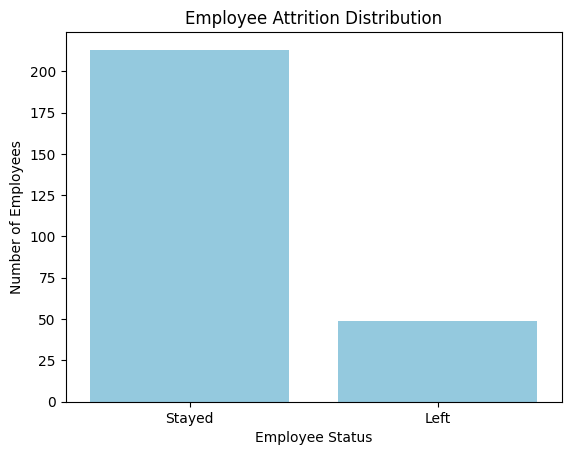

In [ ]:
sns.countplot(
    data=df,
    x="attrition",
    order=["Stayed", "Left"],
    color="skyblue"
)
plt.title("Employee Attrition Distribution")
plt.xlabel("Employee Status")
plt.ylabel("Number of Employees")
plt.show()

Department frequency bar chart

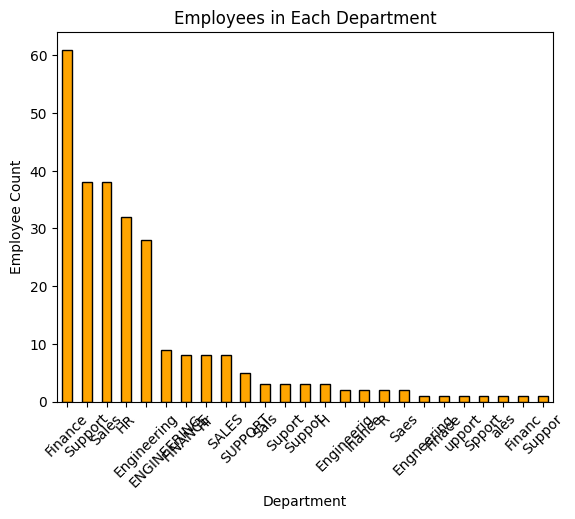

In [ ]:
df["department"].value_counts().plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)
plt.title("Employees in Each Department")
plt.xlabel("Department")
plt.ylabel("Employee Count")
plt.xticks(rotation=45)
plt.show()

Salary histogram with KDE

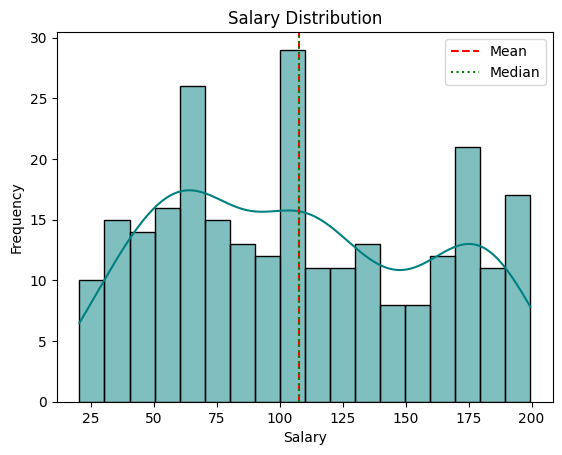

In [ ]:
sns.histplot(
    df["salary_k"].dropna(),
    bins=18,
    kde=True,
    color="teal"
)
plt.axvline(
    df["salary_k"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)
plt.axvline(
    df["salary_k"].median(),
    color="green",
    linestyle=":",
    label="Median"
)
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.legend()
plt.show()

Tenure histogram

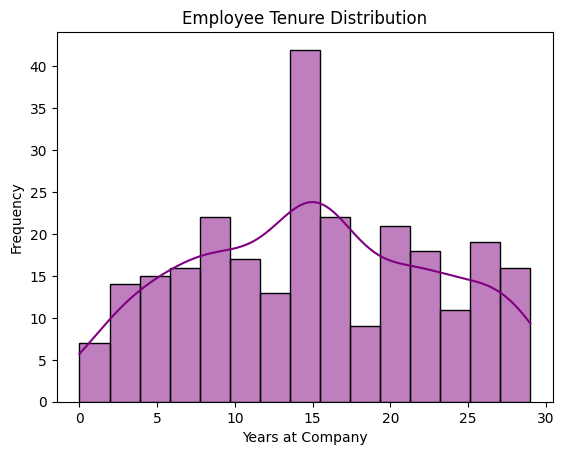

In [ ]:
sns.histplot(
    data=df,
    x="years_at_company",
    bins=15,
    kde=True,
    color="purple"
)
plt.title("Employee Tenure Distribution")
plt.xlabel("Years at Company")
plt.ylabel("Frequency")
plt.show()

Statistical analysis

In [ ]:
cols = [
    "salary_k",
    "years_at_company",
    "last_performance_score"
]
print("Mean:")
print(df[cols].mean())
print("Median:")
print(df[cols].median())
print("Standard Deviation:")
print(df[cols].std())
print("Variance:")
print(df[cols].var())
print("Skewness:")
print(df[cols].skew())
print("Kurtosis:")
print(df[cols].kurt())


Mean:
salary_k                  107.666777
years_at_company           15.072519
last_performance_score      3.100000
dtype: float64
Median:
salary_k                  107.666777
years_at_company           15.000000
last_performance_score      3.000000
dtype: float64
Standard Deviation:
salary_k                  51.679182
years_at_company           7.830000
last_performance_score     1.366821
dtype: float64
Variance:
salary_k                  2670.737869
years_at_company            61.308897
last_performance_score       1.868199
dtype: float64
Skewness:
salary_k                  0.186659
years_at_company          0.029385
last_performance_score   -0.085458
dtype: float64
Kurtosis:
salary_k                 -1.173189
years_at_company         -0.965276
last_performance_score   -1.184345
dtype: float64


Outlier detection using boxplots

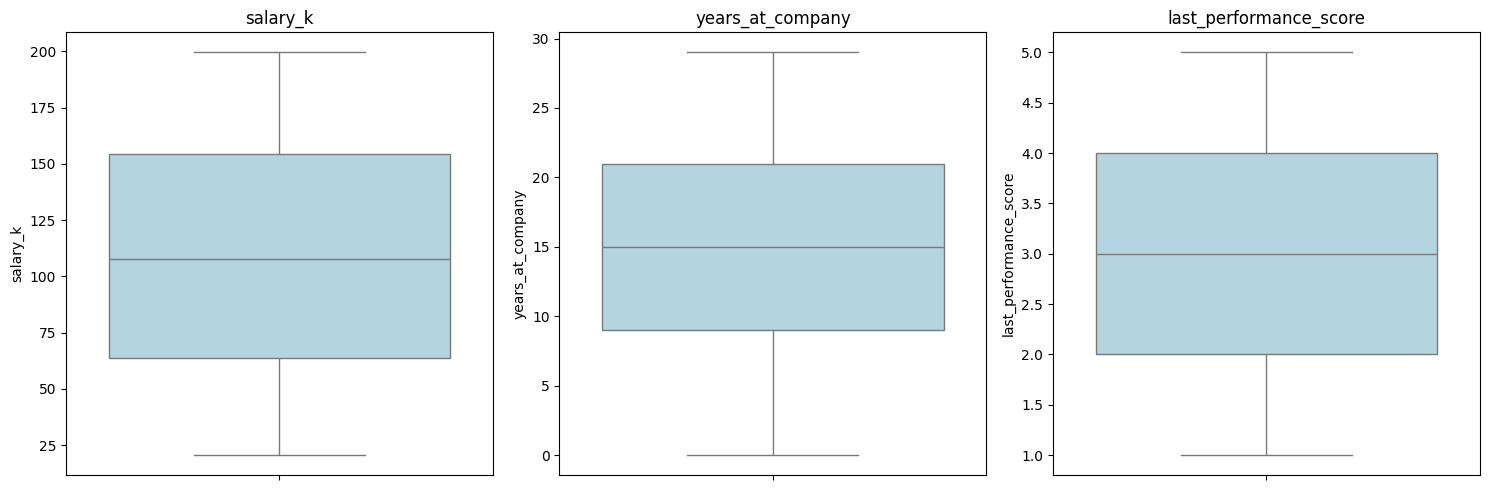

In [ ]:
cols = [
    "salary_k",
    "years_at_company",
    "last_performance_score"
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax, color="lightblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

Outlier detection using IQR

In [ ]:
for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]
    print(col, "Possible outliers:", len(outliers))

salary_k Possible outliers: 0
years_at_company Possible outliers: 0
last_performance_score Possible outliers: 0


Bivariate analysis

Salary vs attrition – violin plot

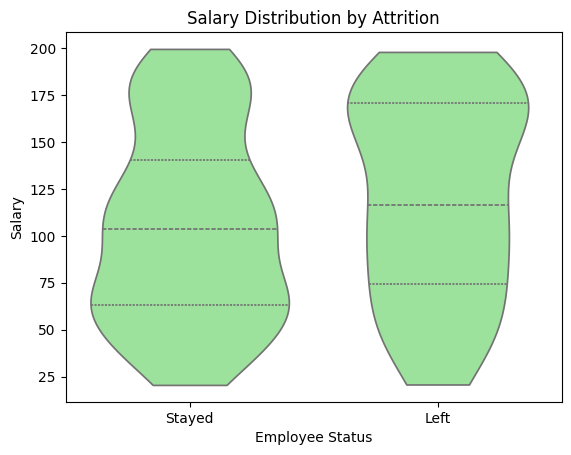

In [ ]:
sns.violinplot(
    data=df,
    x="attrition",
    y="salary_k",
    order=["Stayed", "Left"],
    color="lightgreen",
    inner="quartile",
    cut=0
)
plt.title("Salary Distribution by Attrition")
plt.xlabel("Employee Status")
plt.ylabel("Salary")
plt.show()

Tenure vs attrition – boxplot

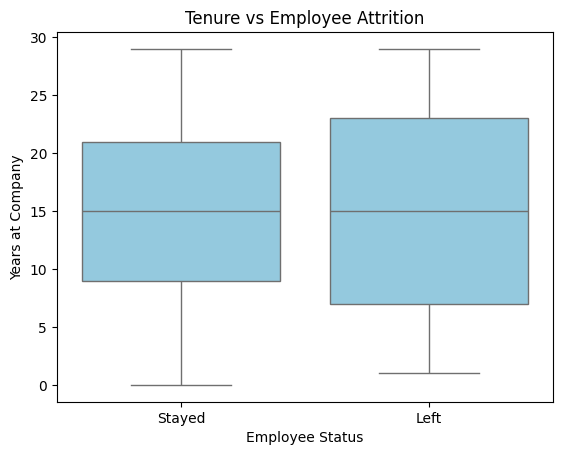

In [ ]:
sns.boxplot(
    data=df,
    x="attrition",
    y="years_at_company",
    order=["Stayed", "Left"],
    color="skyblue"
)
plt.title("Tenure vs Employee Attrition")
plt.xlabel("Employee Status")
plt.ylabel("Years at Company")
plt.show()


Promotion vs attrition – grouped count plot




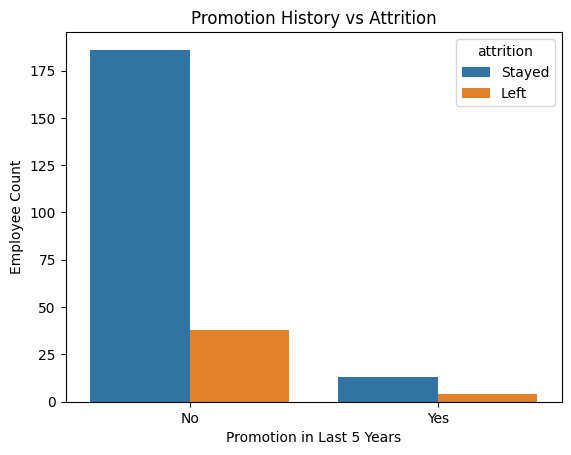

In [ ]:
sns.countplot(
    data=df,
    x="promotion_last_5years",
    hue="attrition",
    order=["No", "Yes"]
)

plt.title("Promotion History vs Attrition")
plt.xlabel("Promotion in Last 5 Years")
plt.ylabel("Employee Count")
plt.show()

Work accident vs attrition – stacked bar chart

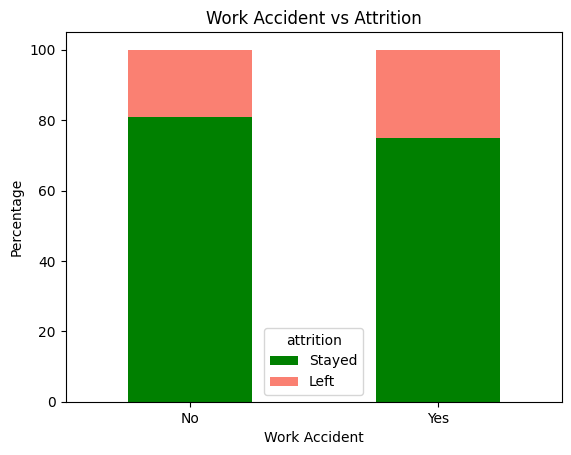

In [ ]:
accident = pd.crosstab(
    df["work_accident"],
    df["attrition"],
    normalize="index"
) * 100
accident = accident.reindex(
    index=["No", "Yes"],
    columns=["Stayed", "Left"]
)
accident.plot(
    kind="bar",
    stacked=True,
    color=["green", "salmon"]
)
plt.title("Work Accident vs Attrition")
plt.xlabel("Work Accident")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()

Multivariate analysis

Correlation heatmap

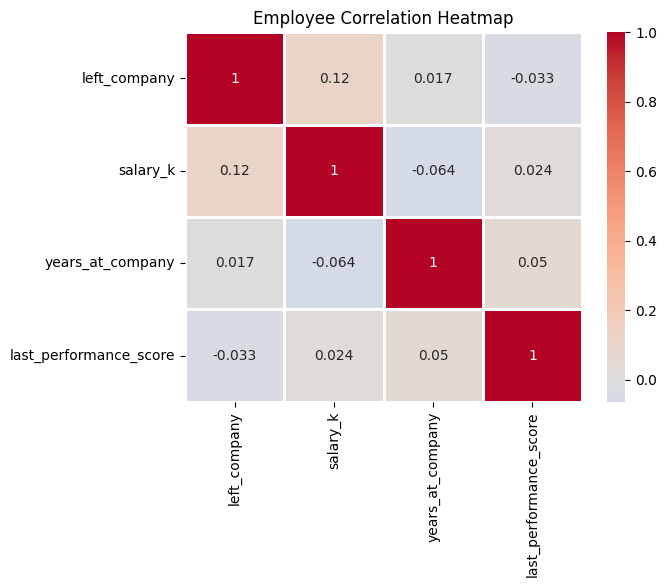

In [ ]:
cols = [
    "left_company",
    "salary_k",
    "years_at_company",
    "last_performance_score"
]
corr = df[cols].corr()
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    linewidths=1
)
plt.title("Employee Correlation Heatmap")
plt.show()

Pair plot

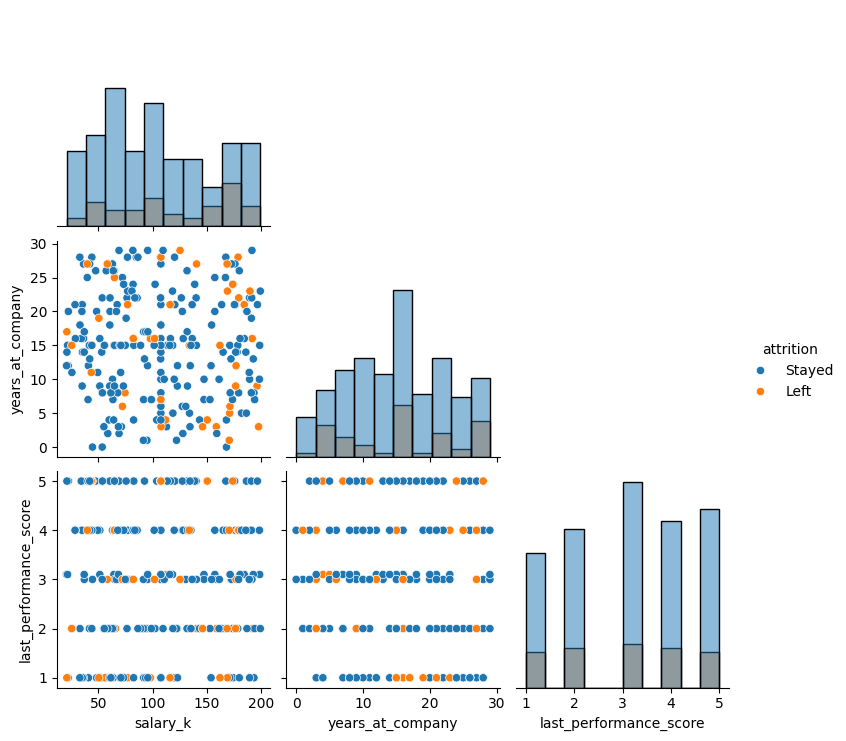

In [ ]:
cols = [
    "salary_k",
    "years_at_company",
    "last_performance_score",
    "attrition"
]
pair_df = df[cols].dropna()
sns.pairplot(
    pair_df,
    hue="attrition",
    corner=True,
    diag_kind="hist"
)
plt.show()

Multivariate scatter plot

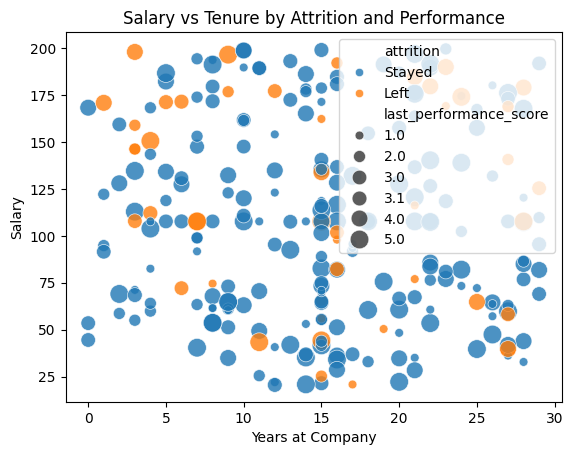

In [ ]:
sns.scatterplot(
    data=df,
    x="years_at_company",
    y="salary_k",
    hue="attrition",
    size="last_performance_score",
    sizes=(40, 180),
    alpha=0.8
)
plt.title("Salary vs Tenure by Attrition and Performance")
plt.xlabel("Years at Company")
plt.ylabel("Salary")
plt.show()

Equal-width and equal-frequency binning

This EDA shows how employee attrition can be explored using univariate, bivariate and multivariate techniques. The most useful visual comparisons are department-wise attrition rate, salary and tenure distributions by attrition, promotion history, work-accident history and the correlation heatmap.